# Лабораторная работа №3
## Экономика информатизации
### Расчёт критической массы и ценности социальной сети

**Задача.** Компания «ГородСоцСеть» запускает социальную сеть для жителей города с населением 1 млн человек.
Нужно оценить экономическую ценность сети и определить момент достижения критической массы.

## Исходные данные

| Параметр | Значение |
|---|---|
| Общий потенциал рынка (M) | 1 000 000 чел. |
| Начальное число пользователей (N₀) | 5 000 чел. |
| Ежемесячный темп прироста (до критической массы) | 3% |
| Ежемесячный темп прироста (после критической массы) | 15% |
| Коэффициент ценности сети (k) | 0,005 руб./пользователь² |
| Затраты на поддержание сети в месяц | 2 000 000 руб. |
| Стоимость привлечения одного пользователя (CAC) | 500 руб. |
| Средний доход с одного пользователя в месяц (ARPU) | 15 руб. |
| Время горизонта | 36 месяцев (3 года) |
| Ставка дисконтирования | 12% годовых (1% в месяц) |

In [1]:
# Исходные данные
M = 1_000_000           # общий потенциал рынка, чел.
N0 = 5_000               # начальное число пользователей, чел.
g_before = 0.03           # ежемесячный прирост до критической массы
g_after = 0.15            # ежемесячный прирост после критической массы
k = 0.005                 # коэффициент ценности сети (закон Меткалфа), руб./польз.^2
maintenance = 2_000_000   # затраты на поддержание сети в месяц, руб.
CAC = 500                 # стоимость привлечения одного пользователя, руб.
ARPU = 15                 # средний доход с пользователя в месяц, руб.
months = 36                # горизонт, мес.
r_m = 0.01                 # ставка дисконтирования, в месяц (12% годовых = 1% в месяц)

print(f"Горизонт: {months} мес. ({months/12:.0f} года), ставка дисконтирования: {r_m:.1%} в месяц")

Горизонт: 36 мес. (3 года), ставка дисконтирования: 1.0% в месяц


## Часть 1. Расчёт критической массы

### 1.1. Минимальное число пользователей N\*

Сеть становится самоподдерживающейся, когда месячный доход покрывает затраты на поддержание сети **и**
стоимость привлечения очередного (маржинального) пользователя:

$$R(N^*) \geq \text{Затраты на поддержание} + CAC$$

$$ARPU \times N^* = \text{Затраты на поддержание} + CAC \quad\Rightarrow\quad N^* = \frac{\text{Затраты на поддержание} + CAC}{ARPU}$$

**Допущение:** CAC здесь учитывается как стоимость привлечения одного дополнительного (маржинального)
пользователя, а не как суммарные затраты на весь прирост пользователей за месяц — иначе (если учитывать CAC
на каждого нового пользователя месяца) условие становится рекурсивным и при заданных параметрах не выполняется
никогда, так как рост сам генерирует пользователей, требующих CAC.

In [2]:
N_star = (maintenance + CAC) / ARPU

print(f"N* (критическая масса) = {N_star:,.0f} чел.".replace(",", " "))
print(f"Это {N_star / M:.1%} от общего потенциала рынка M")

N* (критическая масса) = 133 367 чел.
Это 13.3% от общего потенциала рынка M


### 1.2. Через сколько месяцев сеть достигнет критической массы

При экспоненциальном росте $N_t = N_0 \times (1+g)^t$ время достижения N\* находится из:

$$t = \frac{\ln(N^*/N_0)}{\ln(1+g)}$$

In [3]:
import math

def months_to_reach(N_target, N_start, g):
    return math.log(N_target / N_start) / math.log(1 + g)

t_before = months_to_reach(N_star, N0, g_before)
t_after = months_to_reach(N_star, N0, g_after)

print(f"При темпе роста {g_before:.0%} в месяц: {t_before:.1f} мес. (~{t_before/12:.1f} года)")
print(f"При темпе роста {g_after:.0%} в месяц (гипотетически, если бы применялся с начала): {t_after:.1f} мес. (~{t_after/12:.1f} года)")
print()
print(f"При базовом темпе {g_before:.0%}/мес. критическая масса НЕ будет достигнута в пределах "
      f"{months}-месячного горизонта проекта (111 мес. >> 36 мес.).")
print("Темп 15%/мес. фактически применяется только ПОСЛЕ пересечения N*, то есть в рамках 3-летнего "
      "горизонта сеть продолжит расти по базовой (медленной) траектории.")

При темпе роста 3% в месяц: 111.1 мес. (~9.3 года)
При темпе роста 15% в месяц (гипотетически, если бы применялся с начала): 23.5 мес. (~2.0 года)

При базовом темпе 3%/мес. критическая масса НЕ будет достигнута в пределах 36-месячного горизонта проекта (111 мес. >> 36 мес.).
Темп 15%/мес. фактически применяется только ПОСЛЕ пересечения N*, то есть в рамках 3-летнего горизонта сеть продолжит расти по базовой (медленной) траектории.


## Часть 2. Оценка ценности сети

Для каждого месяца при заданных темпах роста (с переключением на ускоренный рост после пересечения N\*,
если это произойдёт в пределах горизонта) рассчитываем:

- Ценность сети по закону Меткалфа: $V(N) = k \times N^2$
- Доход от пользователей: $R(N) = ARPU \times N$
- Прибыль сети: $\Pi(N) = R(N) - \text{Затраты на поддержание} - CAC \times \Delta N$, где $\Delta N$ — число новых пользователей за месяц

In [4]:
def simulate(arpu, g_before, g_after, n_star, months=months, N0=N0, M=M,
             maintenance=maintenance, CAC=CAC, r_m=r_m):
    """Помесячная симуляция роста сети с переключением темпа при достижении критической массы."""
    N = N0
    reached = False
    crit_month = None
    rows = []  # (месяц, N, dN, V, R, Pi, дисконт. Pi)
    npv = 0.0
    for t in range(1, months + 1):
        g = g_after if reached else g_before
        N_prev = N
        N = min(N_prev * (1 + g), M)
        dN = N - N_prev
        V = k * N ** 2
        R = arpu * N
        Pi = R - maintenance - CAC * dN
        disc_Pi = Pi / (1 + r_m) ** t
        npv += disc_Pi
        rows.append((t, N, dN, V, R, Pi, disc_Pi))
        if not reached and R >= maintenance + CAC:
            reached = True
            crit_month = t
    return rows, npv, crit_month

rows_base, npv_base, crit_month_base = simulate(ARPU, g_before, g_after, N_star)

print(f"{'Мес':>4} | {'N, чел.':>10} | {'ΔN':>7} | {'V(N), руб.':>16} | {'R(N), руб.':>12} | {'Π(N), руб.':>13}")
for row in rows_base[::3]:  # каждый 3-й месяц для компактности
    t, N, dN, V, R, Pi, _ = row
    print(f"{t:>4} | {N:>10,.0f} | {dN:>7,.0f} | {V:>16,.0f} | {R:>12,.0f} | {Pi:>13,.0f}".replace(",", " "))
print("...")
t, N, dN, V, R, Pi, _ = rows_base[-1]
print(f"{t:>4} | {N:>10,.0f} | {dN:>7,.0f} | {V:>16,.0f} | {R:>12,.0f} | {Pi:>13,.0f}".replace(",", " "))

print(f"\nКритическая масса достигнута в пределах горизонта: {crit_month_base}")

 Мес |    N, чел. |      ΔN |       V(N), руб. |   R(N), руб. |    Π(N), руб.
   1 |      5 150 |     150 |          132 612 |       77 250 |    -1 997 750
   4 |      5 628 |     164 |          158 346 |       84 413 |    -1 997 541
   7 |      6 149 |     179 |          189 074 |       92 241 |    -1 997 313
  10 |      6 720 |     196 |          225 764 |      100 794 |    -1 997 064
  13 |      7 343 |     214 |          269 574 |      110 140 |    -1 996 792
  16 |      8 024 |     234 |          321 885 |      120 353 |    -1 996 495
  19 |      8 768 |     255 |          384 348 |      131 513 |    -1 996 170
  22 |      9 581 |     279 |          458 932 |      143 708 |    -1 995 814
  25 |     10 469 |     305 |          547 988 |      157 033 |    -1 995 426
  28 |     11 440 |     333 |          654 327 |      171 595 |    -1 995 002
  31 |     12 500 |     364 |          781 300 |      187 506 |    -1 994 539
  34 |     13 660 |     398 |          932 913 |      204 893 | 

### Визуализация: рост пользователей и ценность сети

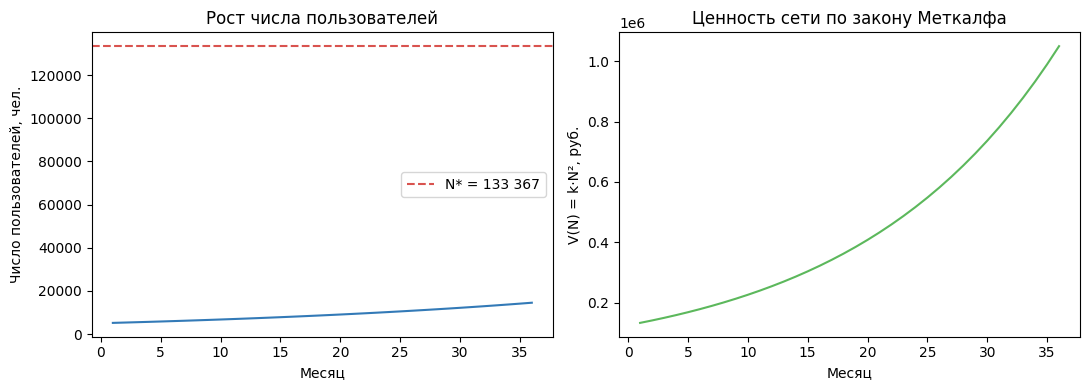

In [5]:
import matplotlib.pyplot as plt

t_vals = [r[0] for r in rows_base]
N_vals = [r[1] for r in rows_base]
V_vals = [r[3] for r in rows_base]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(t_vals, N_vals, color="#337ab7")
axes[0].axhline(N_star, color="#d9534f", linestyle="--", label=f"N* = {N_star:,.0f}".replace(",", " "))
axes[0].set_xlabel("Месяц")
axes[0].set_ylabel("Число пользователей, чел.")
axes[0].set_title("Рост числа пользователей")
axes[0].legend()

axes[1].plot(t_vals, V_vals, color="#5cb85c")
axes[1].set_xlabel("Месяц")
axes[1].set_ylabel("V(N) = k·N², руб.")
axes[1].set_title("Ценность сети по закону Меткалфа")

plt.tight_layout()
plt.show()

## Часть 3. Анализ эффективности

### 3.1. NPV проекта за 36 месяцев (базовый сценарий: 3% / 15%, r = 1% в месяц)

$$NPV = \sum_{t=1}^{36} \frac{\Pi_t}{(1+r_m)^t}$$

In [6]:
print(f"NPV (базовый сценарий, ARPU={ARPU} руб.): {npv_base:,.0f} руб.".replace(",", " "))
print(f"N(36) = {rows_base[-1][1]:,.0f} чел. ({rows_base[-1][1]/M:.1%} от рынка)".replace(",", " "))
print()
print("Проект ЭКОНОМИЧЕСКИ НЕ ОКУПАЕТСЯ за 3 года: сеть не достигает критической массы "
      "(133 367 чел.), остаётся на уровне первых процентов от неё, и ежемесячный доход "
      "(ARPU × N) не покрывает фиксированные затраты на поддержание в 2 млн руб./мес.")

NPV (базовый сценарий  ARPU=15 руб.): -60 099 621 руб.
N(36) = 14 491 чел. (1.4% от рынка)

Проект ЭКОНОМИЧЕСКИ НЕ ОКУПАЕТСЯ за 3 года: сеть не достигает критической массы (133 367 чел.), остаётся на уровне первых процентов от неё, и ежемесячный доход (ARPU × N) не покрывает фиксированные затраты на поддержание в 2 млн руб./мес.


### 3.2. Чувствительность NPV к темпу роста

Сравним базовый, пессимистичный (2% / 10%) и оптимистичный (5% / 20%) сценарии.

In [7]:
scenarios = {
    "Пессимистичный (2% / 10%)": (0.02, 0.10),
    "Базовый (3% / 15%)": (0.03, 0.15),
    "Оптимистичный (5% / 20%)": (0.05, 0.20),
}

print(f"{'Сценарий':<28} | {'NPV, руб.':>16} | {'N(36), чел.':>12} | {'Крит. масса достигнута':>24}")
for name, (gb, ga) in scenarios.items():
    rows, npv, crit_month = simulate(ARPU, gb, ga, N_star)
    N_end = rows[-1][1]
    status = f"мес. {crit_month}" if crit_month else "нет"
    print(f"{name:<28} | {npv:>16,.0f} | {N_end:>12,.0f} | {status:>24}".replace(",", " "))

Сценарий                     |        NPV, руб. |  N(36), чел. |   Крит. масса достигнута
Пессимистичный (2% / 10%)    |      -59 086 830 |       10 199 |                      нет
Базовый (3% / 15%)           |      -60 099 621 |       14 491 |                      нет
Оптимистичный (5% / 20%)     |      -63 739 312 |       28 959 |                      нет


**Наблюдение:** даже в оптимистичном сценарии NPV оказывается *ниже* (более отрицательным), чем в базовом.
Это не ошибка: пока сеть не пересекла критическую массу, более быстрый рост означает больше новых
пользователей каждый месяц — а значит, больше расходов на их привлечение (CAC × ΔN) без соответствующего
роста дохода, покрывающего фиксированные затраты на поддержание. Быстрый рост «ниже порога» ускоряет не
прибыль, а убытки.

### 3.3. Минимальный ARPU для безубыточности проекта

Найдём методом бисекции минимальный ARPU, при котором NPV проекта за 36 месяцев (при базовых темпах роста
3% / 15%) становится неотрицательным. Обратите внимание: рост ARPU одновременно повышает доход **и**
снижает порог критической массы N\* = (Затраты на поддержание + CAC) / ARPU, поэтому функция NPV(ARPU)
монотонно возрастает, и поиск методом бисекции корректен.

In [8]:
def npv_for_arpu(arpu, g_before=g_before, g_after=g_after):
    n_star = (maintenance + CAC) / arpu
    _, npv, _ = simulate(arpu, g_before, g_after, n_star)
    return npv

lo, hi = 1.0, 500.0
assert npv_for_arpu(lo) < 0 and npv_for_arpu(hi) > 0, "Нет корня в интервале поиска"

for _ in range(200):
    mid = (lo + hi) / 2
    if npv_for_arpu(mid) < 0:
        lo = mid
    else:
        hi = mid

arpu_breakeven = (lo + hi) / 2
n_star_be = (maintenance + CAC) / arpu_breakeven
_, npv_be, crit_month_be = simulate(arpu_breakeven, g_before, g_after, n_star_be)

print(f"Минимальный безубыточный ARPU ≈ {arpu_breakeven:.2f} руб./чел./мес. "
      f"(текущий ARPU = {ARPU} руб.)")
print(f"При таком ARPU критическая масса N* = {n_star_be:,.0f} чел., достигается на {crit_month_be}-м месяце".replace(",", " "))
print(f"NPV при этом ARPU ≈ {npv_be:,.0f} руб.".replace(",", " "))

Минимальный безубыточный ARPU ≈ 196.82 руб./чел./мес. (текущий ARPU = 15 руб.)
При таком ARPU критическая масса N* = 10 164 чел.  достигается на 25-м месяце
NPV при этом ARPU ≈ -2 547 678 руб.


*Примечание.* Переход на ускоренный рост (15%/мес.) происходит в конкретном целом месяце, поэтому NPV(ARPU)
меняется не строго непрерывно, а скачками в моменты, когда критическая масса сдвигается на месяц раньше.
Найденное методом бисекции значение ARPU — это точка, в которой NPV пересекает ноль (может быть чуть выше
или ниже нуля из-за этой дискретности), а не точное аналитическое решение.

## Часть 4. Стратегические выводы

### 4.1. Маркетинговые инвестиции для достижения критической массы на 6 месяцев раньше

При базовом темпе роста 3%/мес. критическая масса (N\* = 133 367 чел.) достигается органически примерно
через **t₁ месяцев**. Чтобы сократить этот срок на 6 месяцев, можно единовременно «довложить» платных
пользователей в начале проекта (момент t=0) так, чтобы эффективная стартовая база N₀' была больше, а
дальнейший органический рост (3%/мес.) приводил к N\* на 6 месяцев раньше:

$$N_0' \times (1+g_{before})^{(t_1 - 6)} = N^* \quad\Rightarrow\quad N_0' = \frac{N^*}{(1+g_{before})^{(t_1-6)}}$$

Необходимый маркетинговый бюджет = CAC × (N₀' − N₀).

In [9]:
t1 = months_to_reach(N_star, N0, g_before)
t_target = t1 - 6
N0_needed = N_star / (1 + g_before) ** t_target
extra_users = N0_needed - N0
marketing_budget = CAC * extra_users

print(f"Органический срок достижения критической массы: t1 = {t1:.1f} мес. (~{t1/12:.1f} года)")
print(f"Целевой срок (на 6 месяцев раньше): {t_target:.1f} мес.")
print(f"Требуемая стартовая база пользователей: {N0_needed:,.0f} чел.".replace(",", " "))
print(f"Дополнительные пользователи для платного привлечения: {extra_users:,.0f} чел.".replace(",", " "))
print(f"Необходимый маркетинговый бюджет: {marketing_budget:,.0f} руб.".replace(",", " "))

Органический срок достижения критической массы: t1 = 111.1 мес. (~9.3 года)
Целевой срок (на 6 месяцев раньше): 105.1 мес.
Требуемая стартовая база пользователей: 5 970 чел.
Дополнительные пользователи для платного привлечения: 970 чел.
Необходимый маркетинговый бюджет: 485 131 руб.


### 4.2. Рекомендации по стратегии достижения критической массы

- **Органического роста недостаточно.** При всех трёх сценариях (2%, 3%, 5% в месяц) сеть не достигает
  критической массы за 3 года — требуется от 5,5 до почти 14 лет. Без дополнительных мер проект убыточен
  на всём горизонте оценки (NPV глубоко отрицательный во всех сценариях).
- **Быстрый рост «ниже порога» вреден, а не полезен.** Пока сеть не окупает затраты на поддержание, каждый
  новый пользователь увеличивает расходы на CAC без компенсирующего дохода — поэтому агрессивный маркетинг
  сам по себе, без пересмотра модели монетизации, только ускоряет убытки.
- **Повышение ARPU — наиболее эффективный рычаг.** Рост ARPU одновременно увеличивает доход и снижает
  порог критической массы (N\* обратно пропорционален ARPU). Увеличение ARPU примерно до значения,
  найденного в разделе 3.3 (≈ 197 руб./мес. при неизменных темпах роста), делает проект безубыточным в
  пределах 36 месяцев — например, за счёт премиум-подписки, рекламы в ленте или платных функций для бизнеса.
- **Точечные маркетинговые инвестиции целесообразны только как способ сократить разрыв по времени**
  (например, ≈ 485 тыс. руб. на ускорение достижения критической массы на 6 месяцев), а не как
  самостоятельная стратегия — их эффект нужно оценивать вместе с повышением ARPU и/или снижением затрат
  на поддержание сети.
- **Снижение затрат на поддержание сети** (оптимизация инфраструктуры, переход на более дешёвый хостинг
  при росте масштаба) напрямую снижает N* и также ускоряет момент самоокупаемости.